# Visual Prompt Tuning (VPT) — official implementation, one-click notebook
**Paper followed:** M. Jia, L. Tang, B.-C. Chen, C. Cardie, S. Belongie, B. Hariharan, S.-N. Lim, *Visual Prompt Tuning*, **ECCV 2022** (arXiv:2203.12119).
**Code:** the authors' official repository `github.com/KMnP/vpt` (license CC BY-NC 4.0) — embedded below **byte-for-byte** (the `vpt-main.zip` you supplied) and run **without editing any of its files**.

### What this notebook does (everything in one file, press *Run All*)
1. Unpacks the embedded official repository and verifies its SHA-256.
2. Applies **3 import-compatibility shims** at run time (`turtle`/tkinter, `timm.models.layers.helpers`, `json.load(encoding=)` — the 2022 code predates Python 3.9 / timm 1.x). No repo file is modified.
3. Downloads the official ViT-B/16 **ImageNet-21k** checkpoint and the **Oxford Flowers-102** dataset (one of the paper's FGVC benchmarks) and converts the annotations into the official JSON layout.
4. Verifies the official model against the paper's own statements (parameter counts 0.04 % / 0.53 %, prompt initialisation, prompts per layer, location invariance, frozen backbone) — Section 4b.
5. Trains with the **official `Trainer`, data loaders, solver, evaluator and configs** (`configs/{linear,prompt,finetune}/flowers.yaml`):
   Linear, **VPT-shallow**, **VPT-deep**, Full fine-tuning — the paper's central comparison — plus the paper's Partial-1, Bias and Adapter baselines (all run through the official `MODEL.TRANSFER_TYPE` switch), with a learning-rate grid taken from the official `tune_fgvc.py` lists, selected on the validation split.
6. Produces tables, figures, a prompt-length ablation (paper Fig. 6), t-SNE (paper Fig. 9), a live demo, a storage comparison, a programmatic check of the paper's claims, a proof that **no official source file was modified**, and a downloadable bundle.

### Honest list of what differs from the paper's full protocol
| Item | Paper / official | Here | Why |
|---|---|---|---|
| epochs | 100 (10 warm-up) | 30 (3 warm-up) | Kaggle runtime |
| lr / wd search | 9–10 lrs × 4 wds, per dataset | 3 lrs (official list) × fixed wd 1e-4 | runtime |
| batch size | 128 (A100) | 32, lr scaled by `bs/256` exactly like official `tune_fgvc.py` | 16 GB GPU |
| test evaluation | every epoch | once, at the final epoch (never used for selection) | runtime / no leakage |
| datasets | 5 FGVC + 19 VTAB | Oxford Flowers-102 only | runtime |
| baselines | Full, Linear, Partial-1, Mlp-3, Sidetune, Bias, Adapter | Full, Linear, Partial-1, Bias, Adapter (Mlp-3 / Sidetune not run) | runtime |
| prompt length | tuned per task | 10 (+ ablation 1/5/10/50/100) | runtime |
| seeds | 3 | 1 (`SEEDS` below) | runtime |

> **Academic note:** the model, trainer and configs here are the authors'. State this openly in the report/PPT/viva ("we reproduced the official implementation of Jia et al. on Oxford Flowers-102"); the contribution you can claim is the reproduction, the protocol, the analysis and the demo.

## How to run on Kaggle
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. Right panel → *Session options*: **Accelerator: GPU (T4 ×2 or P100; one GPU is used)** and **Internet: On**.
3. Click **Run All**, or *Save Version → Save & Run All (Commit)* to run in the background (you can close the browser).
4. When done: Output tab → download `vpt_official_outputs.zip` and the executed notebook.
Runtime estimate (not measured): about 5–7 h for the default profile (incl. extra baselines + ablation; set `EXTRA_BASELINES=False` or `PROFILE="fast"` for ~2 h). Interrupted? Just Run All again — finished runs are skipped.

### Where each part of the paper lives in the official code (traceability for the viva)
| Paper | Official file / class | Verified in |
|---|---|---|
| Eq. 1–3 plain ViT (patch embed + positional enc., `[CLS]`, N layers, head) | `src/models/vit_backbones/vit.py` (`Embeddings`, `Block`, `Encoder`, `VisionTransformer`) | §4b + §5 |
| Eq. 4–6 **VPT-shallow** (prompts into layer 1 only) | `src/models/vit_prompt/vit.py` → `PromptedTransformer.incorporate_prompt` | §4b |
| Eq. 7–8 **VPT-deep** (fresh prompts at every layer, old prompt outputs dropped) | same file → `PromptedTransformer.forward_deep_prompt` | §4b |
| "Storing visual prompts" 0.04 % / 0.53 % | `prompt_embeddings`, `deep_prompt_embeddings` parameters | §4b |
| Backbone frozen, only prompts + head trained | `src/models/vit_models.py` (`build_backbone`, transfer types) | §4b |
| Baselines Full / Linear / Partial-1 / Bias / Adapter | `MODEL.TRANSFER_TYPE` = `end2end` / `linear` / `partial-1` / `tinytl-bias` / `adapter` | §5 |
| FGVC protocol (Oxford Flowers, train/val/test, val selects hyper-parameters) | `src/data/datasets/json_dataset.py`, `tune_fgvc.py` | §4, §5 |
| Fig. 6 prompt length | `MODEL.PROMPT.NUM_TOKENS` | §6 |
| Fig. 9 t-SNE of the final `[CLS]` | `ViT.get_features` | §7 |
| Not run here (runtime): Fig. 3 data scales, Fig. 4 backbone scales, Fig. 5/7/8 design ablations, VTAB-1k, Swin, segmentation, self-supervised backbones, ConvNets | other official configs / files | — |

## 1. Embedded official repository (unmodified)

In [1]:
# collapsed: base64 of the official `vpt-main.zip`
REPO_ZIP_SHA256 = "9c6839289c34960eeb3d19d6950daa67604ab5e0e94011bc38b70389660c1ce1"
REPO_B64 = """
...
"""

In [2]:
import base64, hashlib, io, os, shutil, zipfile
data = base64.b64decode("".join(REPO_B64.split()))
assert hashlib.sha256(data).hexdigest() == REPO_ZIP_SHA256, "embedded repo corrupted"
if not os.path.isdir("vpt_official"):
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        z.extractall("_repo_tmp")
    root = os.path.join("_repo_tmp", os.listdir("_repo_tmp")[0])
    shutil.move(root, "vpt_official"); shutil.rmtree("_repo_tmp")
with zipfile.ZipFile(io.BytesIO(data)) as z:        # sha256 of every file as shipped -> compared again at the very end
    prefix = z.namelist()[0].split("/")[0] + "/"
    ZIP_MANIFEST = {n[len(prefix):]: hashlib.sha256(z.read(n)).hexdigest() for n in z.namelist() if not n.endswith("/")}
n_py = sum(f.endswith(".py") for _, _, fs in os.walk("vpt_official") for f in fs)
print(f"official repo ready: {n_py} python files, sha256 {REPO_ZIP_SHA256[:16]}…  (identical to the zip you provided)")
print(open("vpt_official/LICENSE").read().splitlines()[0])

official repo ready: 63 python files, sha256 9c6839289c34960e…  (identical to the zip you provided)
Attribution-NonCommercial 4.0 International


## 2. Glue code (our thin wrapper; calls the official classes in the order of the official `train.py`)

In [3]:
%%writefile official_runner.py
"""
Thin glue around the UNMODIFIED official VPT code (github.com/KMnP/vpt, Jia et al., ECCV 2022).

Nothing inside the official repository is edited. We only
  (1) add three compatibility shims so the 2022 code runs on a modern Python/timm
      (`turtle` needs tkinter; `timm.models.layers.helpers` was removed from timm;
       `json.load(..., encoding=)` was removed in Python 3.9),
  (2) call the official classes in exactly the order of the official train.py:
      get_cfg -> data loaders -> build_model -> Trainer.train_classifier -> Trainer.eval_classifier.
"""
import os
import random
import re
import sys
import time
import types

import numpy as np
import torch

METHOD_CONFIG = {                       # official config file (configs/<dir>/flowers.yaml) per method
    "linear": ("linear", []),
    "vpt_shallow": ("prompt", ["MODEL.PROMPT.DEEP", "False"]),
    "vpt_deep": ("prompt", ["MODEL.PROMPT.DEEP", "True"]),
    "full": ("finetune", []),           # TRANSFER_TYPE "end2end" = full fine-tuning
    # extra baselines of the paper's Table 1 (all implemented by the official repo via MODEL.TRANSFER_TYPE)
    "partial1": ("linear", ["MODEL.TRANSFER_TYPE", "partial-1"]),    # fine-tune the last block + head
    "bias": ("linear", ["MODEL.TRANSFER_TYPE", "tinytl-bias"]),      # bias terms + head (BitFit / TinyTL)
    "adapter": ("linear", ["MODEL.TRANSFER_TYPE", "adapter"]),       # Houlsby/Pfeiffer adapters + head
}


def prepare(repo_dir):
    """Make the official package importable (shims only; no file of the repo is changed)."""
    repo_dir = os.path.abspath(repo_dir)
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    t = types.ModuleType("turtle")
    t.forward = lambda *a, **k: None
    sys.modules.setdefault("turtle", t)
    os.environ.setdefault("SLURMD_NODENAME", "localhost")     # read by the official setup(); value unused here
    try:                                   # timm >= 0.9 removed timm.models.layers.helpers (old timm still has it -> no shim needed)
        import timm.layers as L
        h = types.ModuleType("timm.models.layers.helpers")
        h.to_2tuple = L.to_2tuple
        sys.modules.setdefault("timm.models.layers.helpers", h)
    except ImportError:
        pass
    import functools
    import json as _json
    if not getattr(_json.load, "_vpt_shim", False):          # official io_utils calls json.load(..., encoding=...) (removed in Python 3.9)
        _orig = _json.load

        @functools.wraps(_orig)
        def _load(fp, *a, encoding=None, **k):
            return _orig(fp, *a, **k)
        _load._vpt_shim = True
        _json.load = _load
    return repo_dir


def make_cfg(repo_dir, method, lr, wd, epochs, warmup, batch_size, data_path, model_root, out_dir,
             num_tokens=10, workers=2, feature="sup_vitb16_imagenet21k", num_classes=102, seed=0, num_gpus=None):
    from src.configs.config import get_cfg
    sub, extra = METHOD_CONFIG[method]
    cfg = get_cfg()
    cfg.merge_from_file(os.path.join(repo_dir, "configs", sub, "flowers.yaml"))
    opts = [
        "DATA.DATAPATH", data_path, "DATA.FEATURE", feature, "DATA.NUMBER_CLASSES", str(num_classes),
        "DATA.BATCH_SIZE", str(batch_size), "DATA.NUM_WORKERS", str(workers), "DATA.NO_TEST", "True",
        "MODEL.MODEL_ROOT", model_root, "MODEL.PROMPT.NUM_TOKENS", str(num_tokens),
        "SOLVER.BASE_LR", str(lr / 256 * batch_size),         # same lr scaling rule as official tune_fgvc.py
        "SOLVER.WEIGHT_DECAY", str(wd), "SOLVER.TOTAL_EPOCH", str(epochs), "SOLVER.WARMUP_EPOCH", str(warmup),
        "SOLVER.LOG_EVERY_N", "50", "OUTPUT_DIR", out_dir, "SEED", str(seed),
        "NUM_GPUS", str(num_gpus if num_gpus is not None else 1),       # official loader divides by NUM_GPUS
    ] + extra
    cfg.merge_from_list(opts)
    cfg.freeze()
    return cfg


def _parse_train_loss(log_path):
    out = {}
    if os.path.exists(log_path):
        for m in re.finditer(r"Epoch (\d+) / \d+: .*?average train loss: ([0-9.]+)", open(log_path).read()):
            out[int(m.group(1))] = float(m.group(2))
    return [out[k] for k in sorted(out)]


def run_official(cfg, save_state=True, tsne_n=0):
    """Train one configuration with the official Trainer; evaluate the test split once at the end."""
    from src.data import loader as data_loader
    from src.engine.evaluator import Evaluator
    from src.engine.trainer import Trainer
    from src.models.build_model import build_model
    import src.utils.logging as logging

    os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
    logging.setup_logging(cfg.NUM_GPUS, 1, cfg.OUTPUT_DIR, name="visual_prompt")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    torch.manual_seed(cfg.SEED); np.random.seed(cfg.SEED); random.seed(0)     # as in official train.py

    t0 = time.time()
    train_loader = data_loader.construct_train_loader(cfg)
    val_loader = data_loader.construct_val_loader(cfg)
    test_loader = data_loader.construct_test_loader(cfg)
    model, device = build_model(cfg)
    n_total = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    evaluator = Evaluator()
    trainer = Trainer(cfg, model, evaluator, device)
    trainer.train_classifier(train_loader, val_loader, None)       # official loop (val each epoch)
    total = cfg.SOLVER.TOTAL_EPOCH
    res = evaluator.results
    name = cfg.DATA.NAME
    val_curve = [float(res[f"epoch_{e}"]["classification"][f"val_{name}"]["top1"]) for e in range(total)
                 if f"epoch_{e}" in res and f"val_{name}" in res[f"epoch_{e}"].get("classification", {})]
    diverged = len(val_curve) < total
    out = dict(val_curve=val_curve, diverged=diverged, n_total_params=n_total, n_trainable_params=n_train,
               tuned_percent=100.0 * n_train / n_total)
    if not diverged:
        trainer.eval_classifier(test_loader, "test", True)           # official evaluation, once, final epoch
        out["test_top1"] = float(res[f"epoch_{total - 1}"]["classification"][f"test_{name}"]["top1"])
        out["test_top5"] = float(res[f"epoch_{total - 1}"]["classification"][f"test_{name}"].get("top5", float("nan")))
    out["val_top1_final"] = val_curve[-1] if val_curve else float("nan")
    out["val_top1_best"] = max(val_curve) if val_curve else float("nan")
    out["train_loss_curve"] = _parse_train_loss(os.path.join(cfg.OUTPUT_DIR, "logs.txt"))
    if tsne_n and not diverged:                                   # features of a FIXED test subset (paper Fig. 9), same images for every method
        ds = official_dataset(cfg, "test")
        sel = np.random.default_rng(0).choice(len(ds), size=min(tsne_n, len(ds)), replace=False)
        model.eval()
        feats, labs = [], []
        with torch.no_grad():
            for i in range(0, len(sel), 32):
                items = [ds[int(j)] for j in sel[i:i + 32]]
                x = torch.stack([it["image"] for it in items]).to(device)
                feats.append(model.get_features(x).float().cpu())
                labs += [int(it["label"]) for it in items]
        np.savez_compressed(os.path.join(cfg.OUTPUT_DIR, "tsne_features.npz"), feats=torch.cat(feats).numpy(), labels=np.array(labs))
    out["seconds"] = time.time() - t0
    if save_state and not diverged and cfg.MODEL.TRANSFER_TYPE != "end2end":
        keep = {n for n, p in model.named_parameters() if p.requires_grad}
        torch.save({k: v.cpu() for k, v in model.state_dict().items() if k in keep},
                   os.path.join(cfg.OUTPUT_DIR, "trainable_state.pth"))
    del model, trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out


# --------------------------------------------------------------------------- #
# inference helpers (use the official model class, the official test transform)
# --------------------------------------------------------------------------- #
def load_trained(cfg, state_path=None):
    """Build the official model for `cfg` (loads the pretrained ViT) and load the saved prompts/head."""
    from src.models.build_model import build_model
    model, device = build_model(cfg)
    if state_path:
        sd = torch.load(state_path, map_location="cpu")
        miss = model.load_state_dict(sd, strict=False)
        assert not miss.unexpected_keys, miss.unexpected_keys
    return model.eval(), device


@torch.no_grad()
def features_and_logits(model, device, images):
    """images: normalised float tensor (B,3,224,224) produced by the official test transform."""
    x = images.to(device)
    f = model.get_features(x)
    return model.head(f).float().cpu(), f.float().cpu()


def official_test_transform(size=224):
    from src.data.transforms import get_transforms
    return get_transforms("test", size)


def official_dataset(cfg, split):
    from src.data.datasets.json_dataset import FlowersDataset
    return FlowersDataset(cfg, split)


# --------------------------------------------------------------------------- #
# smoke-test helpers (only used when the notebook is run with VPT_SMOKE=1 on a CPU box)
# --------------------------------------------------------------------------- #
def make_fake_flowers(root, n_classes=10):
    """Tiny dataset in the official FGVC layout (<split>.json + images) for pipeline tests."""
    from PIL import Image
    import json
    rng = np.random.default_rng(0)
    os.makedirs(root, exist_ok=True)
    for split, n in (("train", 4), ("val", 1), ("test", 2)):
        ann = {}
        for c in range(n_classes):
            for i in range(n):
                fn = f"{split}_{c}_{i}.jpg"
                Image.fromarray(rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)).save(os.path.join(root, fn))
                ann[fn] = c
        json.dump(ann, open(os.path.join(root, f"{split}.json"), "w"))


def make_fake_weights(repo_dir, out_path):
    """Random ViT-B/16 weights in the Google .npz layout expected by the official loader."""
    from src.models.vit_backbones.vit import VisionTransformer
    m = VisionTransformer("sup_vitb16_imagenet21k", 224, num_classes=-1)
    sd = {k: v.detach().numpy() for k, v in m.state_dict().items()}
    w = {"embedding/kernel": sd["transformer.embeddings.patch_embeddings.weight"].transpose(2, 3, 1, 0),
         "embedding/bias": sd["transformer.embeddings.patch_embeddings.bias"],
         "cls": sd["transformer.embeddings.cls_token"],
         "Transformer/encoder_norm/scale": sd["transformer.encoder.encoder_norm.weight"],
         "Transformer/encoder_norm/bias": sd["transformer.encoder.encoder_norm.bias"],
         "Transformer/posembed_input/pos_embedding": sd["transformer.embeddings.position_embeddings"]}
    A = "MultiHeadDotProductAttention_1/"
    for i in range(12):
        R_, o = f"Transformer/encoderblock_{i}/", f"transformer.encoder.layer.{i}."
        for nm in ("query", "key", "value"):
            w[R_ + A + nm + "/kernel"] = sd[o + f"attn.{nm}.weight"].T.reshape(768, 12, 64)
            w[R_ + A + nm + "/bias"] = sd[o + f"attn.{nm}.bias"].reshape(12, 64)
        w[R_ + A + "out/kernel"] = sd[o + "attn.out.weight"].T.reshape(12, 64, 768)
        w[R_ + A + "out/bias"] = sd[o + "attn.out.bias"]
        for a, b in (("Dense_0", "fc1"), ("Dense_1", "fc2")):
            w[R_ + f"MlpBlock_3/{a}/kernel"] = sd[o + f"ffn.{b}.weight"].T
            w[R_ + f"MlpBlock_3/{a}/bias"] = sd[o + f"ffn.{b}.bias"]
        for a, b in (("LayerNorm_0", "attention_norm"), ("LayerNorm_2", "ffn_norm")):
            w[R_ + a + "/scale"] = sd[o + b + ".weight"]
            w[R_ + a + "/bias"] = sd[o + b + ".bias"]
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    np.savez(out_path, **w)


# --------------------------------------------------------------------------- #
# verification helpers
# --------------------------------------------------------------------------- #
def paper_conformance(repo_dir, model_root=None, num_classes=102, verbose=True):
    """
    Checks the OFFICIAL implementation against statements of the paper (Sec. 3, 'Storing Visual Prompts').
    Returns a list of (claim, passed, detail). Never raises (a failing check is reported, not fatal).
    """
    import math
    from types import SimpleNamespace
    from src.models.vit_prompt.vit import PromptedVisionTransformer
    out = []

    def check(name, ok, info=""):
        out.append((name, bool(ok), info))
        if verbose:
            print(f"[{'PASS' if ok else 'FAIL'}] {name}  {info}")

    p, d, L, m_tokens = 50, 768, 12, 196
    for deep in (False, True):
        tag = "VPT-deep" if deep else "VPT-shallow"
        cfg = SimpleNamespace(LOCATION="prepend", INITIATION="random", NUM_DEEP_LAYERS=None, DEEP_SHARED=False,
                              NUM_TOKENS=p, DROPOUT=0.0, PROJECT=-1, DEEP=deep, VIT_POOL_TYPE="original")
        torch.manual_seed(0)
        net = PromptedVisionTransformer(cfg, "sup_vitb16_imagenet21k", img_size=224, num_classes=num_classes).eval()
        backbone = sum(q.numel() for n, q in net.named_parameters() if "prompt" not in n and not n.startswith("head"))
        extra = net.transformer.prompt_embeddings.numel() + (net.transformer.deep_prompt_embeddings.numel() if deep else 0)
        want = L * p * d if deep else p * d
        pct = 100.0 * extra / backbone
        check(f"{tag}: ViT-B backbone has ~86 M parameters", abs(backbone / 1e6 - 85.8) < 0.3, f"{backbone / 1e6:.2f} M")
        check(f"{tag}: p=50 prompts add {want:,} parameters ({'N*p*d' if deep else 'p*d'})", extra == want, f"{extra:,}")
        check(f"{tag}: = {0.53 if deep else 0.04}% of the backbone (paper Sec. 3.2)", abs(pct - (0.53 if deep else 0.04)) < (0.02 if deep else 0.01), f"{pct:.3f}%")
        bound = math.sqrt(6.0 / (3 * 16 * 16 + d))
        mx = max(net.transformer.prompt_embeddings.abs().max().item(),
                 net.transformer.deep_prompt_embeddings.abs().max().item() if deep else 0)
        check(f"{tag}: prompts initialised U(-v, v), v = sqrt(6/(3*16^2+d))", mx <= bound + 1e-6, f"max|p|={mx:.4f} <= {bound:.4f}")
        seen = {}
        hooks = [blk.register_forward_pre_hook(lambda mod, inp, i=i: seen.__setitem__(i, inp[0].detach()))
                 for i, blk in enumerate(net.transformer.encoder.layer)]
        x = torch.randn(2, 3, 224, 224)
        with torch.no_grad():
            net(x)
        [h.remove() for h in hooks]
        check(f"{tag}: every layer sees [CLS] + {p} prompts + {m_tokens} patches", all(v.shape[1] == 1 + p + m_tokens for v in seen.values()),
              f"seq len {seen[0].shape[1]}")
        first = torch.allclose(seen[0][:, 1:1 + p], net.transformer.prompt_embeddings.expand(2, -1, -1))
        if deep:
            later = all(torch.allclose(seen[i][:, 1:1 + p], net.transformer.deep_prompt_embeddings[i - 1].expand(2, -1, -1)) for i in range(1, L))
            check("VPT-deep: layer i receives its own fresh prompts P_(i-1) (Eq. 7)", first and later)
        else:
            check("VPT-shallow: prompts enter layer 1 only (Eq. 4-6)", first)
            with torch.no_grad():                                    # location invariance claimed in Sec. 3.2
                ref = net.transformer(x)[0][:, 0]
                z = torch.cat([net.transformer.embeddings(x), net.transformer.prompt_embeddings.expand(2, -1, -1)], 1)   # [x0, E0, P]
                for blk in net.transformer.encoder.layer:
                    z, _ = blk(z)
                alt = net.transformer.encoder.encoder_norm(z)[:, 0]
            check("[x0,P,E0] and [x0,E0,P] give the same [CLS] output (paper Sec. 3.2)", torch.allclose(ref, alt, atol=1e-4),
                  f"max|diff|={(ref - alt).abs().max().item():.1e}")
        del net
    if model_root is not None:                                      # frozen-backbone check on the real build_model path
        from src.models.build_model import build_model
        for method, want_names in (("vpt_deep", {"prompt_embeddings", "deep_prompt_embeddings", "head"}), ("vpt_shallow", {"prompt_embeddings", "head"}), ("linear", {"head"})):
            cfg = make_cfg(repo_dir, method, 1.0, 1e-4, 1, 1, 2, ".", model_root, "conformance_tmp", num_tokens=p, workers=0, num_classes=num_classes)
            net, _ = build_model(cfg)
            names = {n for n, q in net.named_parameters() if q.requires_grad}
            kinds = {("deep_prompt_embeddings" if "deep_prompt_embeddings" in n else "prompt_embeddings" if "prompt_embeddings" in n else "head" if "head" in n else n) for n in names}
            check(f"{method}: only {sorted(want_names)} are trainable (backbone frozen)", kinds == want_names, f"{len(names)} tensors")
            del net
    return out


def file_manifest(root, skip=("__pycache__",)):
    """sha256 of every file below `root` (used to prove the official sources were not modified)."""
    import hashlib
    man = {}
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d not in skip]
        for f in fn:
            if f.endswith(".pyc"):
                continue
            path = os.path.join(dp, f)
            man[os.path.relpath(path, root)] = hashlib.sha256(open(path, "rb").read()).hexdigest()
    return man

Writing official_runner.py


In [4]:
%%writefile demo_official.py
#!/usr/bin/env python
"""
Demo: classify an image with a trained VPT model, using the OFFICIAL model code (github.com/KMnP/vpt).

python demo_official.py --repo vpt_official --weights weights --method vpt_deep \
       --state results/official/vpt_deep/<run>/trainable_state.pth --image my_flower.jpg [--topk 5]

Only the prompts + head are stored in `trainable_state.pth` (a few hundred KB); the frozen ViT-B/16
(ImageNet-21k) is loaded from `weights/imagenet21k_ViT-B_16.npz`.
"""
import argparse
import os

import torch
from PIL import Image

import official_runner as R


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--repo", default="vpt_official")
    ap.add_argument("--weights", default="weights", help="folder with imagenet21k_ViT-B_16.npz")
    ap.add_argument("--method", default="vpt_deep", choices=list(R.METHOD_CONFIG))
    ap.add_argument("--state", required=True)
    ap.add_argument("--image", required=True)
    ap.add_argument("--prompts", type=int, default=10)
    ap.add_argument("--classes", type=int, default=102)
    ap.add_argument("--topk", type=int, default=5)
    a = ap.parse_args()
    repo = R.prepare(a.repo)
    cfg = R.make_cfg(repo, a.method, 0.1, 1e-4, 1, 0, 1, ".", os.path.abspath(a.weights), "demo_out",
                     num_tokens=a.prompts, workers=0, num_classes=a.classes)
    model, device = R.load_trained(cfg, a.state)
    x = R.official_test_transform(224)(Image.open(a.image).convert("RGB")).unsqueeze(0)
    logits, _ = R.features_and_logits(model, device, x)
    p, i = torch.softmax(logits, -1)[0].topk(a.topk)
    for pr, ix in zip(p, i):
        print(f"class {int(ix):3d}   {100 * float(pr):5.1f}%")


if __name__ == "__main__":
    main()

Writing demo_official.py


## 3. Configuration

In [5]:
import os, sys, json, time, subprocess, importlib.util, warnings
warnings.filterwarnings("ignore")
for pkg, spec in [("fvcore", "fvcore"), ("iopath", "iopath"), ("yacs", "yacs"), ("ml_collections", "ml_collections"),
                  ("simplejson", "simplejson"), ("termcolor", "termcolor"), ("sklearn", "scikit-learn"),
                  ("pandas", "pandas"), ("scipy", "scipy"), ("timm", "timm")]:      # needed by the official code
    if importlib.util.find_spec(pkg) is None:
        subprocess.call([sys.executable, "-m", "pip", "install", "-q", spec])
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import official_runner as R
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

SMOKE = os.environ.get("VPT_SMOKE", "0") == "1"       # tiny CPU pipeline test; leave OFF for the real run
PROFILE = "standard"                                   # "standard" (~3-5 h) or "fast" (~1-2 h)
PROFILES = {
    # base lrs come from the official tune_fgvc.py lists; effective lr = base_lr / 256 * batch_size (official rule)
    "standard": dict(epochs=30, warmup=3, grids={"linear": [25., 5., 1.], "vpt_shallow": [25., 5., 1.],
                                                  "vpt_deep": [25., 5., 1.], "full": [0.005, 0.001, 0.0001],
                                                  "partial1": [1., 0.1], "bias": [1., 0.1], "adapter": [1., 0.1]}),
    "fast":     dict(epochs=15, warmup=2, grids={"linear": [25., 5.], "vpt_shallow": [25., 5.],
                                                  "vpt_deep": [25., 5.], "full": [0.005, 0.001],
                                                  "partial1": [1.], "bias": [1.], "adapter": [1.]}),
}
P = PROFILES[PROFILE]
EXTRA_BASELINES = True                                 # paper Table 1 baselines Partial-1 / Bias / Adapter (+~1.5 h)
METHODS = ["linear", "vpt_shallow", "vpt_deep", "full"] + (["partial1", "bias", "adapter"] if EXTRA_BASELINES else [])
LABELS = {"linear": "Linear", "partial1": "Partial-1", "bias": "Bias", "adapter": "Adapter",
          "vpt_shallow": "VPT-shallow (official)", "vpt_deep": "VPT-deep (official)", "full": "Full fine-tuning"}
NUM_PROMPTS, WD, BS, WORKERS, SEEDS = 10, 1e-4, 32, 2, [0]
RUN_ABLATION, ABLATION_LENGTHS = True, [1, 5, 50, 100, 200]          # paper Fig. 6 uses 1, 5, 10, 50, 100, 200
EPOCHS, WARMUP, GRID = P["epochs"], P["warmup"], P["grids"]
NUM_CLASSES, N_TSNE, DATA_ROOT, WEIGHTS_DIR = 102, 1500, "data", "weights"
RES, FIG = "results", "figures"
if SMOKE:
    EPOCHS, WARMUP, BS, WORKERS, NUM_CLASSES, N_TSNE = 2, 1, 8, 0, 10, 20
    GRID = {m: g[:1] for m, g in GRID.items()}; ABLATION_LENGTHS = [1]
    torch.cuda.device_count = lambda: 1            # TEST ONLY (CPU sandbox): official build_model asserts NUM_GPUS <= device_count
for d in (RES, FIG, DATA_ROOT, WEIGHTS_DIR, f"{RES}/runs"):
    os.makedirs(d, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print(f"profile={PROFILE}  epochs={EPOCHS}  batch={BS}  prompts={NUM_PROMPTS}  grids={GRID}")
if device.type != "cuda" and not SMOKE:
    raise RuntimeError("No GPU. Kaggle: Session options > Accelerator > GPU.")

torch 2.11.0+cu128 | device cuda (Tesla T4)
profile=standard  epochs=30  batch=32  prompts=10  grids={'linear': [25.0, 5.0, 1.0], 'vpt_shallow': [25.0, 5.0, 1.0], 'vpt_deep': [25.0, 5.0, 1.0], 'full': [0.005, 0.001, 0.0001], 'partial1': [1.0, 0.1], 'bias': [1.0, 0.1], 'adapter': [1.0, 0.1]}


## 4. Pre-flight: official checkpoint (ViT-B/16, ImageNet-21k) and dataset (Oxford Flowers-102)

In [6]:
import urllib.request
CKPT = f"{WEIGHTS_DIR}/imagenet21k_ViT-B_16.npz"          # name required by the official MODEL_ZOO (see official README)
URL = "https://storage.googleapis.com/vit_models/imagenet21k/ViT-B_16.npz"
repo = R.prepare("vpt_official")
if SMOKE:      # test-only: random weights in the official .npz layout, built in a subprocess to keep this kernel small
    subprocess.check_call([sys.executable, "-c", f"import official_runner as R; R.prepare('vpt_official'); R.make_fake_weights('vpt_official', '{CKPT}')"])
elif not os.path.exists(CKPT):
    err = None
    for attempt in range(3):
        try:
            urllib.request.urlretrieve(URL, CKPT + ".part"); os.replace(CKPT + ".part", CKPT); err = None; break
        except Exception as e:
            err = e; print(f"download attempt {attempt + 1}/3 failed: {type(e).__name__}"); time.sleep(5)
    if err is not None:
        e = err
        raise RuntimeError(f"Could not download {URL} ({type(e).__name__}). Kaggle: turn Internet ON in Session options. "
                           f"Alternative: upload ViT-B_16.npz as a Kaggle dataset and copy it to {CKPT}.")
w = np.load(CKPT)
assert "cls" in w.files and any(k.startswith("Transformer/encoderblock_11") for k in w.files), "unexpected checkpoint format"
print(f"checkpoint OK: {os.path.getsize(CKPT) / 1e6:.0f} MB, {len(w.files)} tensors")

checkpoint OK: 413 MB, 202 tensors


In [7]:
# ---- Oxford Flowers-102 -> official FGVC layout:  <DATAPATH>/{train,val,test}.json  mapping image path -> class id ----
if SMOKE:
    DATA_PATH = os.path.abspath(f"{DATA_ROOT}/flowers_fake"); R.make_fake_flowers(DATA_PATH, NUM_CLASSES)
else:
    import torchvision
    splits = {s: torchvision.datasets.Flowers102(DATA_ROOT, split=s, download=True) for s in ("train", "val", "test")}
    base = splits["train"]._base_folder
    DATA_PATH = os.path.abspath(str(base))
    for s, ds in splits.items():
        ann = {str(p.relative_to(base)): int(l) for p, l in zip(ds._image_files, ds._labels)}   # torchvision's own file list + labels
        json.dump(ann, open(f"{DATA_PATH}/{s}.json", "w"))
files = {s: set(json.load(open(f"{DATA_PATH}/{s}.json"))) for s in ("train", "val", "test")}
labels = {s: set(json.load(open(f"{DATA_PATH}/{s}.json")).values()) for s in files}
leak = {("train", "val"): len(files["train"] & files["val"]), ("train", "test"): len(files["train"] & files["test"]),
        ("val", "test"): len(files["val"] & files["test"])}
assert all(v == 0 for v in leak.values()), f"split overlap! {leak}"
assert all(len(l) == NUM_CLASSES for l in labels.values()), "every split must contain all classes (official class-id mapping is built per split)"
print({s: len(f) for s, f in files.items()}, "| classes:", NUM_CLASSES, "| split overlaps:", leak)
display(pd.DataFrame([dict(split=s, images=len(f)) for s, f in files.items()]))

100%|██████████| 345M/345M [00:09<00:00, 36.2MB/s] 
100%|██████████| 502/502 [00:00<00:00, 1.44MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 28.8MB/s]


{'train': 1020, 'val': 1020, 'test': 6149} | classes: 102 | split overlaps: {('train', 'val'): 0, ('train', 'test'): 0, ('val', 'test'): 0}


,split,images
0,train,1020
1,val,1020
2,test,6149


## 4b. Does the official model do what the paper says? (programmatic verification)
Runs on the official classes with random weights (parameter counts, init, per-layer prompts, location invariance) and on the real `build_model` path with the downloaded checkpoint (frozen backbone). A failing line is reported but does not stop the notebook.

In [8]:
conf = R.paper_conformance(repo, model_root=os.path.abspath(WEIGHTS_DIR), num_classes=NUM_CLASSES)
json.dump([dict(claim=c, passed=p_, detail=d_) for c, p_, d_ in conf], open(f"{RES}/paper_conformance.json", "w"), indent=1)
print(f"\n{sum(p_ for _, p_, _ in conf)}/{len(conf)} paper-conformance checks passed")

[PASS] VPT-shallow: ViT-B backbone has ~86 M parameters  85.80 M
[PASS] VPT-shallow: p=50 prompts add 38,400 parameters (p*d)  38,400
[PASS] VPT-shallow: = 0.04% of the backbone (paper Sec. 3.2)  0.045%
[PASS] VPT-shallow: prompts initialised U(-v, v), v = sqrt(6/(3*16^2+d))  max|p|=0.0625 <= 0.0625
[PASS] VPT-shallow: every layer sees [CLS] + 50 prompts + 196 patches  seq len 247
[PASS] VPT-shallow: prompts enter layer 1 only (Eq. 4-6)  
[PASS] [x0,P,E0] and [x0,E0,P] give the same [CLS] output (paper Sec. 3.2)  max|diff|=3.9e-06
[PASS] VPT-deep: ViT-B backbone has ~86 M parameters  85.80 M
[PASS] VPT-deep: p=50 prompts add 460,800 parameters (N*p*d)  460,800
[PASS] VPT-deep: = 0.53% of the backbone (paper Sec. 3.2)  0.537%
[PASS] VPT-deep: prompts initialised U(-v, v), v = sqrt(6/(3*16^2+d))  max|p|=0.0625 <= 0.0625
[PASS] VPT-deep: every layer sees [CLS] + 50 prompts + 196 patches  seq len 247
[PASS] VPT-deep: layer i receives its own fresh prompts P_(i-1) (Eq. 7)  
[PASS] vpt_deep:

## 5. Official-code experiments
Each run = official `get_cfg` → `construct_*_loader` → `build_model` → `Trainer.train_classifier` (validation after every epoch) → `Trainer.eval_classifier` on the test split **once**. The learning rate per method is chosen on validation accuracy; the test split is never used for selection. Finished runs are cached in `results/*.json` (resume-safe).

In [9]:
def run_name(method, lr, p):
    return f"{method}_lr{lr:g}" + (f"_p{p}" if method.startswith("vpt") else "")

def do_run(method, lr, p, seed=0, bs=None):
    bs = bs or BS
    name = run_name(method, lr, p) + (f"_s{seed}" if seed else "") + (f"_bs{bs}" if bs != BS else "")
    jpath = f"{RES}/{name}.json"
    if os.path.exists(jpath):
        return json.load(open(jpath))
    cfg = R.make_cfg(repo, method, lr, WD, EPOCHS, WARMUP, bs, DATA_PATH, os.path.abspath(WEIGHTS_DIR),
                     os.path.abspath(f"{RES}/runs/{name}"), num_tokens=p, workers=WORKERS, num_classes=NUM_CLASSES, seed=seed)
    out = R.run_official(cfg, tsne_n=N_TSNE)
    rec = dict(name=name, method=method, base_lr=lr, effective_lr=lr / 256 * bs, wd=WD, epochs=EPOCHS, batch_size=bs,
               prompts=p if method.startswith("vpt") else 0, seed=seed, **out)
    json.dump(rec, open(jpath, "w"), indent=1)
    return rec

def do_run_safe(method, lr, p, seed=0):
    # long prompt sequences (e.g. 200 prompts -> ~400 tokens) can exceed a 16 GB GPU at batch 32: retry once with half the batch
    try:
        return do_run(method, lr, p, seed)
    except RuntimeError as e:
        if "out of memory" not in str(e).lower() or BS < 2:
            raise
        print(f"CUDA out of memory with p={p}, batch {BS} -> retrying with batch {BS // 2} (lr scaled by the official bs/256 rule)")
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        return do_run(method, lr, p, seed, bs=BS // 2)

T0, records = time.time(), []
for method in METHODS:
    for lr in GRID[method]:
        for seed in SEEDS:
            rec = do_run(method, lr, NUM_PROMPTS, seed)
            records.append(rec)
            print(f"[{method:11s} base_lr={lr:<7g}] val={100 * rec['val_top1_final']:6.2f}%  "
                  + ("DIVERGED" if rec["diverged"] else f"test={100 * rec['test_top1']:6.2f}%")
                  + f"  tuned={rec['tuned_percent']:.3f}%  {rec['seconds'] / 60:.1f} min")
print(f"\nall main runs finished/loaded in {(time.time() - T0) / 60:.1f} min")

[10/25 17:32:31 visual_prompt]: Constructing OxfordFlowers dataset train...
[10/25 17:32:31 visual_prompt]: Number of images: 1020
[10/25 17:32:31 visual_prompt]: Number of classes: 102
[10/25 17:32:31 visual_prompt]: Constructing OxfordFlowers dataset val...
[10/25 17:32:31 visual_prompt]: Number of images: 1020
[10/25 17:32:31 visual_prompt]: Number of classes: 102
[10/25 17:32:31 visual_prompt]: Constructing OxfordFlowers dataset test...
[10/25 17:32:31 visual_prompt]: Number of images: 6149
[10/25 17:32:31 visual_prompt]: Number of classes: 102
[10/25 17:32:32 visual_prompt]: Total Parameters: 85877094	 Gradient Parameters: 78438
[10/25 17:32:32 visual_prompt]: tuned percent:0.091
[10/25 17:32:32 visual_prompt]: Device used for model: 0
[10/25 17:32:32 visual_prompt]: 	Setting up the optimizer...
[10/25 17:32:32 visual_prompt]: Training 1 / 30 epoch, with learning rate 0.0
[10/25 17:32:44 visual_prompt]: Epoch 1 / 30: avg data time: 1.50e-02, avg batch time: 0.3794, average train l

### 5.1 Learning-rate selection (validation only) and final results

In [19]:
df = pd.DataFrame(records)
df["val_%"] = 100 * df["val_top1_final"]; df["test_%"] = 100 * df["test_top1"]
grid_table = df.pivot_table(index="method", columns="base_lr", values="val_%").reindex(METHODS)
print("validation accuracy (%) per base lr  (selection criterion):"); display(grid_table.round(2))

ok = df[~df["diverged"]].copy()
best_rows = []
for m in METHODS:
    sub = ok[ok.method == m]
    if len(sub) == 0:
        print(f"WARNING: every learning rate diverged for '{m}' - it is left out of the final table"); continue
    lr_val = sub.groupby("base_lr")["val_%"].mean()                       # mean over seeds -> unbiased lr choice
    lr_best = sorted(lr_val.index, key=lambda l: (-lr_val[l], l))[0]       # ties -> smaller lr
    at_best = sub[sub.base_lr == lr_best].sort_values("seed")
    row = at_best.iloc[0].copy()                                           # seed-0 run = representative (curves, saved prompts)
    row["test_std"] = at_best["test_%"].std() if len(at_best) > 1 else float("nan")
    row["test_%"], row["val_%"], row["n_seeds"] = at_best["test_%"].mean(), at_best["val_%"].mean(), len(at_best)
    best_rows.append(row)
best = pd.DataFrame(best_rows).reset_index(drop=True)
best["method_label"] = best["method"].map(LABELS)
final = best[["method_label", "test_%", "test_std", "val_%", "base_lr", "tuned_percent", "n_trainable_params", "n_seeds", "seconds"]].copy()
final["train_min"] = (final.pop("seconds") / 60).round(1)
final.to_csv(f"{RES}/final_results.csv", index=False)
display(final.round(3))

validation accuracy (%) per base lr  (selection criterion):


base_lr,0.0001,0.0010,0.0050,0.1000,1.0000,5.0000,25.0000
method,,,,,,,
linear,NaN,NaN,NaN,NaN,97.94,98.33,98.63
vpt_shallow,NaN,NaN,NaN,NaN,98.24,98.63,98.63
vpt_deep,NaN,NaN,NaN,NaN,97.84,98.63,99.12
full,93.14,98.33,93.92,NaN,NaN,NaN,NaN
partial1,NaN,NaN,NaN,97.75,98.63,NaN,NaN
bias,NaN,NaN,NaN,98.14,99.12,NaN,NaN
adapter,NaN,NaN,NaN,97.16,99.12,NaN,NaN


,method_label,test_%,test_std,val_%,base_lr,tuned_percent,n_trainable_params,n_seeds,train_min
0,Linear,97.951,NaN,98.627,25.000,0.091,78438,1,15.7
1,VPT-shallow (official),98.032,NaN,98.627,5.000,0.100,86118,1,24.0
2,VPT-deep (official),98.618,NaN,99.118,25.000,0.198,170598,1,24.2
3,Full fine-tuning,97.512,NaN,98.333,0.001,100.000,85877094,1,29.2
4,Partial-1,97.951,NaN,98.627,1.000,8.347,7167846,1,17.1
5,Bias,98.992,NaN,99.118,1.000,0.211,181350,1,23.7
6,Adapter,98.357,NaN,99.118,1.000,2.120,1858278,1,23.6


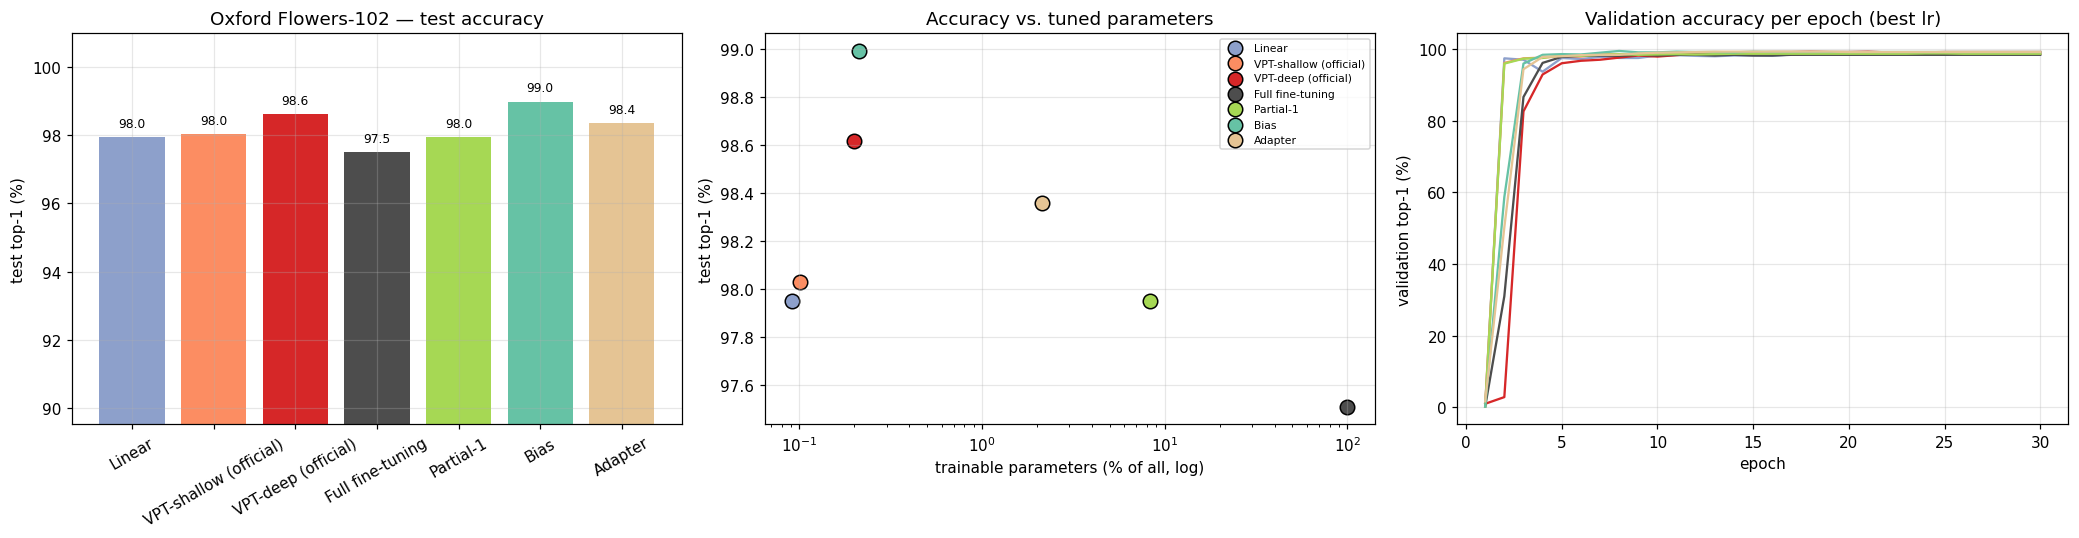

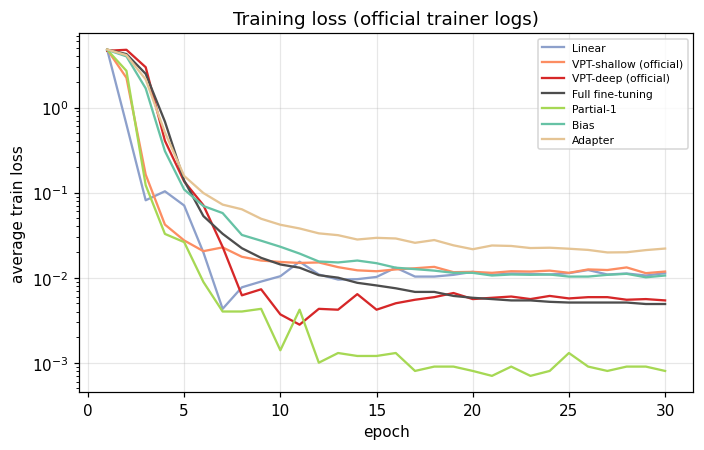

In [20]:
colors = {"linear": "#8da0cb", "partial1": "#a6d854", "bias": "#66c2a5", "adapter": "#e5c494",
          "vpt_shallow": "#fc8d62", "vpt_deep": "#d62728", "full": "#4d4d4d"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
b = ax[0].bar(best["method_label"], best["test_%"], color=[colors[m] for m in best["method"]])
for r_, v in zip(b, best["test_%"]): ax[0].text(r_.get_x() + r_.get_width() / 2, v + .3, f"{v:.1f}", ha="center", fontsize=8)
ax[0].set_ylim(max(0, best["test_%"].min() - 8), 101); ax[0].set_ylabel("test top-1 (%)"); ax[0].set_title("Oxford Flowers-102 — test accuracy")
ax[0].tick_params(axis="x", rotation=30)
for _, r_ in best.iterrows():
    ax[1].scatter(r_["tuned_percent"], r_["test_%"], c=colors[r_["method"]], s=90, edgecolor="k", label=r_["method_label"])
ax[1].set_xscale("log"); ax[1].set_xlabel("trainable parameters (% of all, log)"); ax[1].set_ylabel("test top-1 (%)")
ax[1].set_title("Accuracy vs. tuned parameters"); ax[1].legend(fontsize=7)
for _, r_ in best.iterrows():
    ax[2].plot(range(1, len(r_["val_curve"]) + 1), [100 * v for v in r_["val_curve"]], c=colors[r_["method"]], label=r_["method_label"])
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("validation top-1 (%)"); ax[2].set_title("Validation accuracy per epoch (best lr)")
fig.tight_layout(); fig.savefig(f"{FIG}/accuracy_overview.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for _, r_ in best.iterrows():
    ax.plot(range(1, len(r_["train_loss_curve"]) + 1), r_["train_loss_curve"], c=colors[r_["method"]], label=r_["method_label"])
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("average train loss"); ax.set_title("Training loss (official trainer logs)"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f"{FIG}/training_curves.png", bbox_inches="tight"); plt.show()

### 5.2 Are the paper's claims reproduced?
Evaluated on **our** numbers (single dataset). Paper reference, Table 1, FGVC average (ViT-B/16, 5 datasets): Full 88.54 · Linear 79.32 · Partial-1 82.63 · Bias 88.41 · Adapter 85.66 · VPT-shallow 84.62 · **VPT-deep 89.11**.

In [21]:
g = {m: best.loc[best.method == m].iloc[0] for m in best["method"]}
CORE = ("linear", "vpt_shallow", "vpt_deep", "full")
assert all(m in g for m in CORE), "a core method (Linear / VPT-shallow / VPT-deep / Full) diverged for every lr - lower the lr grid and re-run"
peft = [m for m in ("linear", "partial1", "bias", "adapter") if m in g]
claims = pd.DataFrame([{
    "C1 deep > every other parameter-efficient method run (" + ", ".join(LABELS[m] for m in peft) + ")": all(g["vpt_deep"]["test_%"] > g[m]["test_%"] for m in peft),
    "C1b deep > Linear": g["vpt_deep"]["test_%"] > g["linear"]["test_%"],
    "C2 deep >= Full": g["vpt_deep"]["test_%"] >= g["full"]["test_%"],
    "C2b deep - Full (pts)": round(g["vpt_deep"]["test_%"] - g["full"]["test_%"], 2),
    "C2c deep tunes < 1 % of params": g["vpt_deep"]["tuned_percent"] < 1.0,
    "C3 deep >= shallow": g["vpt_deep"]["test_%"] >= g["vpt_shallow"]["test_%"],
    "best method": best.loc[best["test_%"].idxmax(), "method_label"]}], index=["OxfordFlowers"])
claims

,"C1 deep > every other parameter-efficient method run (Linear, Partial-1, Bias, Adapter)",C1b deep > Linear,C2 deep >= Full,C2b deep - Full (pts),C2c deep tunes < 1 % of params,C3 deep >= shallow,best method
OxfordFlowers,False,True,True,1.11,True,True,Bias


> **Reading the claims honestly.** Oxford Flowers-102 is a small, easy dataset on which a strong ImageNet-21k ViT is typically very accurate, so differences of a few tenths of a point can be within run-to-run noise with a single seed (the paper itself averages three runs). Report the numbers as measured; a `False` in this table is a legitimate finding, not an error. Use `SEEDS = [0, 1, 2]` for mean ± std.

## 6. Ablation — prompt length (paper Fig. 6), VPT-deep at its selected learning rate
Analysis only: the learning rate is the one chosen on validation for `p=10`; no test-based selection.

{'prompts': 1, 'tuned_percent': 0.1020581743469943, 'val_pct': 98.4313725490196, 'test_pct': 98.04846316474224}
[10/26 01:03:25 visual_prompt]: Constructing OxfordFlowers dataset train...
[10/26 01:03:25 visual_prompt]: Number of images: 1020
[10/26 01:03:25 visual_prompt]: Number of classes: 102
[10/26 01:03:25 visual_prompt]: Constructing OxfordFlowers dataset val...
[10/26 01:03:25 visual_prompt]: Number of images: 1020
[10/26 01:03:25 visual_prompt]: Number of classes: 102
[10/26 01:03:25 visual_prompt]: Constructing OxfordFlowers dataset test...
[10/26 01:03:25 visual_prompt]: Number of images: 6149
[10/26 01:03:25 visual_prompt]: Number of classes: 102
[10/26 01:03:27 visual_prompt]: Total Parameters: 85923174	 Gradient Parameters: 124518
[10/26 01:03:27 visual_prompt]: tuned percent:0.145
[10/26 01:03:27 visual_prompt]: Device used for model: 0
[10/26 01:03:27 visual_prompt]: 	Setting up the optimizer...
[10/26 01:03:27 visual_prompt]: Training 1 / 30 epoch, with learning rate 0

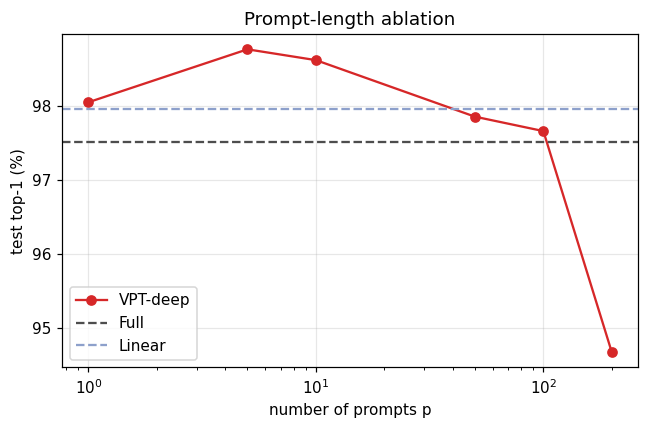

,prompts,tuned_percent,val_pct,test_pct
0,1,0.102,98.431,98.048
1,5,0.145,99.216,98.764
2,10,0.198,99.118,98.618
3,50,0.625,97.941,97.853
4,100,1.152,97.255,97.658
5,200,2.191,96.275,94.666


In [22]:
abl = None
if RUN_ABLATION:
    lr_deep = float(g["vpt_deep"]["base_lr"]); rows = []
    for p in sorted(set(ABLATION_LENGTHS + [NUM_PROMPTS])):
        r_ = do_run_safe("vpt_deep", lr_deep, p)
        rows.append(dict(prompts=p, tuned_percent=r_["tuned_percent"], val_pct=100 * r_["val_top1_final"],
                         test_pct=float("nan") if r_["diverged"] else 100 * r_["test_top1"]))
        print(rows[-1])
    abl = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(abl["prompts"], abl["test_pct"], "o-", c=colors["vpt_deep"], label="VPT-deep")
    ax.axhline(g["full"]["test_%"], ls="--", c=colors["full"], label="Full"); ax.axhline(g["linear"]["test_%"], ls="--", c=colors["linear"], label="Linear")
    ax.set_xscale("log"); ax.set_xlabel("number of prompts p"); ax.set_ylabel("test top-1 (%)"); ax.set_title("Prompt-length ablation"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{FIG}/ablation_prompt_length.png", bbox_inches="tight"); plt.show()
    display(abl.round(3))

## 7. Feature visualisation — t-SNE of the final embedding (paper Fig. 9)
Features are produced by the **official model class** (`get_features`) right after each official training run, for the same fixed set of test images; the paper's Fig. 9 shows Linear, Full, VPT-shallow, VPT-deep.

[10/26 03:29:18 visual_prompt]: Constructing OxfordFlowers dataset test...
[10/26 03:29:18 visual_prompt]: Number of images: 6149
[10/26 03:29:18 visual_prompt]: Number of classes: 102


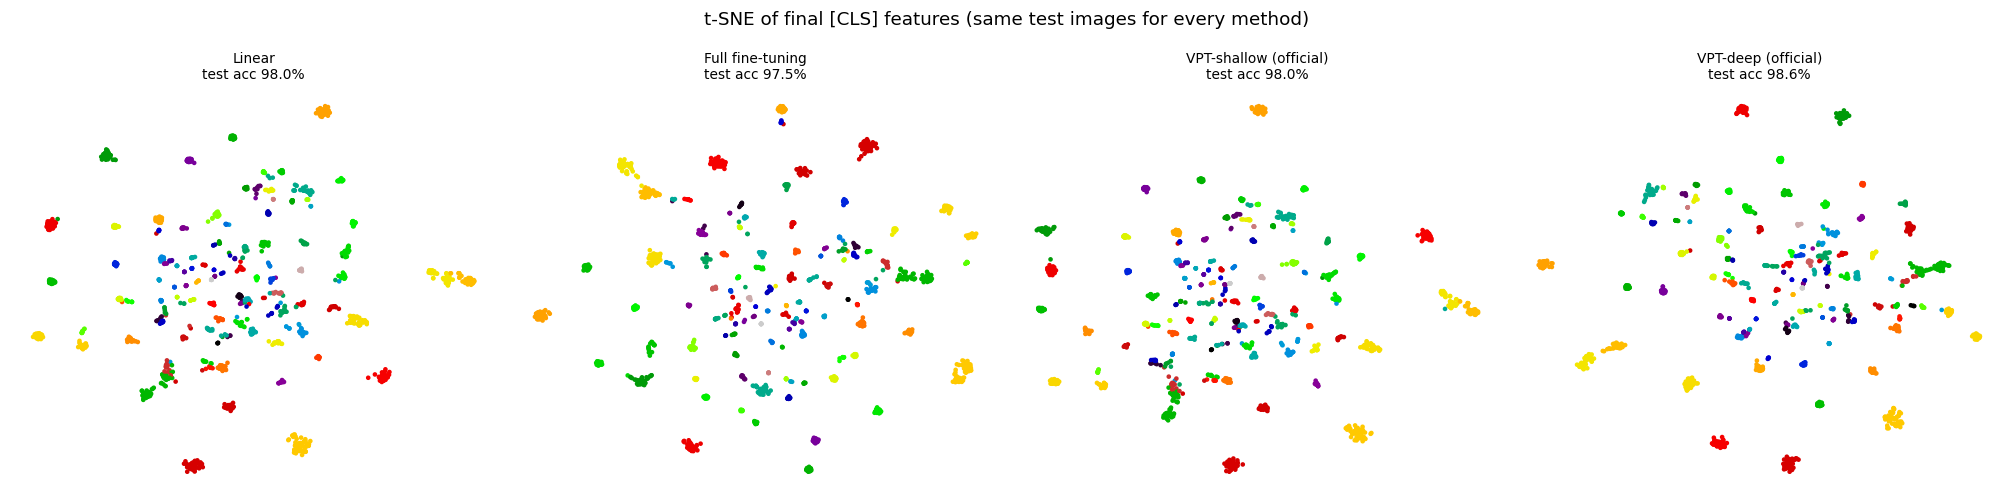

In [28]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
def best_cfg(method):
    r_ = g[method]
    return R.make_cfg(repo, method, float(r_["base_lr"]), WD, EPOCHS, WARMUP, BS, DATA_PATH, os.path.abspath(WEIGHTS_DIR),
                      os.path.abspath(f"{RES}/runs/{r_['name']}"), num_tokens=NUM_PROMPTS, workers=0, num_classes=NUM_CLASSES)
test_ds = R.official_dataset(best_cfg("linear"), "test")          # also used by the demo below
panel = [m for m in ("linear", "full", "vpt_shallow", "vpt_deep") if m in g]
fig, axes = plt.subplots(1, len(panel), figsize=(4.6 * len(panel), 4.6))
for ax, m in zip(np.atleast_1d(axes), panel):
    z = np.load(f"{RES}/runs/{g[m]['name']}/tsne_features.npz")
    f, labs = z["feats"], z["labels"]
    f = PCA(n_components=min(50, f.shape[0] - 1), random_state=0).fit_transform(f)
    e = TSNE(2, init="pca", perplexity=min(30, (len(f) - 1) / 3), random_state=0).fit_transform(f)
    ax.scatter(e[:, 0], e[:, 1], c=plt.cm.nipy_spectral(labs / max(1, labs.max())), s=4); ax.axis("off")
    ax.set_title(f"{g[m]['method_label']}\ntest acc {g[m]['test_%']:.1f}%", fontsize=9)
fig.suptitle("t-SNE of final [CLS] features (same test images for every method)"); fig.tight_layout()
fig.savefig(f"{FIG}/tsne.png", bbox_inches="tight"); plt.show()

## 8. Live demo & storage argument

[10/26 03:29:54 visual_prompt]: Total Parameters: 85969254	 Gradient Parameters: 170598
[10/26 03:29:54 visual_prompt]: tuned percent:0.198
[10/26 03:29:54 visual_prompt]: Device used for model: 0


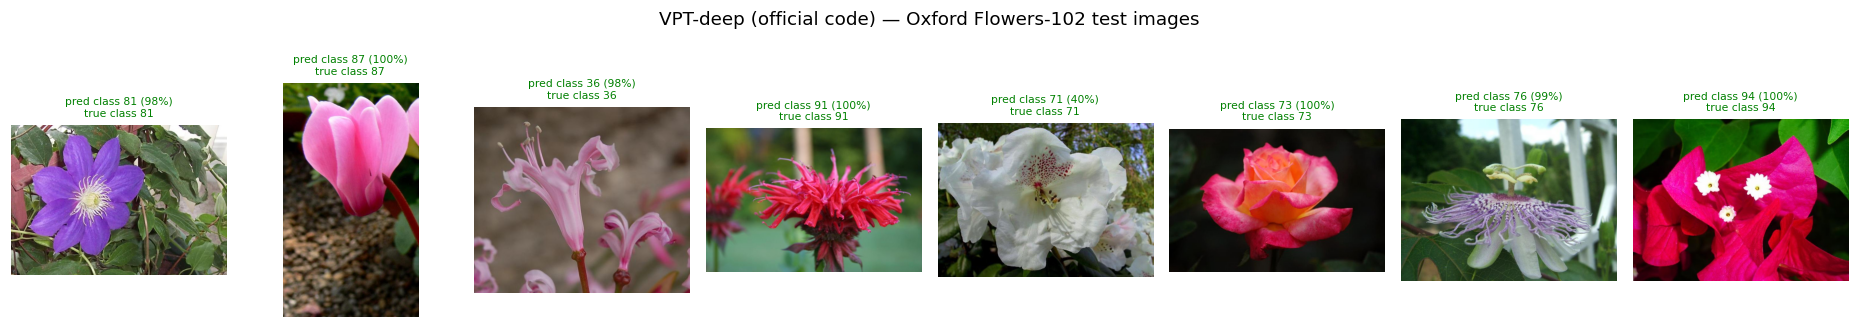

VPT-deep per-task file (prompts + head): 0.68 MB   vs   one full ViT-B copy: 344 MB
storage for 24 tasks: full fine-tuning 8,244 MB | VPT-deep 360 MB -> 22.9x smaller (paper Table 1: 24.02x vs 1.18x)

CLI demo for your own picture:  python demo_official.py --repo vpt_official --weights weights --method vpt_deep --state results/runs/vpt_deep_lr25_p10/trainable_state.pth --image my_flower.jpg


In [31]:
from PIL import Image
cfg = best_cfg("vpt_deep")
model, dev = R.load_trained(cfg, f"{RES}/runs/{g['vpt_deep']['name']}/trainable_state.pth")
pick = np.random.default_rng(7).choice(len(test_ds), size=8, replace=False)
logits, _ = R.features_and_logits(model, dev, torch.stack([test_ds[int(i)]["image"] for i in pick]))
probs = torch.softmax(logits, -1); top = probs.topk(3, dim=-1)
fig, axes = plt.subplots(1, 8, figsize=(17, 3))
for k, ax in enumerate(axes):
    i = int(pick[k]); ax.imshow(Image.open(test_ds._imdb[i]["im_path"]).convert("RGB")); ax.axis("off")
    pred, true = int(top.indices[k, 0]), int(test_ds._imdb[i]["class"])
    ax.set_title(f"pred class {pred} ({100 * float(top.values[k, 0]):.0f}%)\ntrue class {true}", fontsize=7, color="green" if pred == true else "red")
fig.suptitle("VPT-deep (official code) — Oxford Flowers-102 test images"); fig.tight_layout()
fig.savefig(f"{FIG}/demo_predictions.png", bbox_inches="tight"); plt.show()

state = f"{RES}/runs/{g['vpt_deep']['name']}/trainable_state.pth"
full_mb = g["full"]["n_total_params"] * 4 / 1e6
T_ = 24; per_task = os.path.getsize(state) / 1e6
print(f"VPT-deep per-task file (prompts + head): {per_task:.2f} MB   vs   one full ViT-B copy: {full_mb:.0f} MB")
print(f"storage for {T_} tasks: full fine-tuning {T_ * full_mb:,.0f} MB | VPT-deep {full_mb + T_ * per_task:,.0f} MB "
      f"-> {T_ * full_mb / (full_mb + T_ * per_task):.1f}x smaller (paper Table 1: 24.02x vs 1.18x)")
print("\nCLI demo for your own picture:  python demo_official.py --repo vpt_official --weights weights --method vpt_deep "
      f"--state {state} --image my_flower.jpg")

## 9. Summary file (copy these numbers into the report / PPT)

In [32]:
def md_table(frame, index=False):
    f = frame.reset_index() if index else frame
    return "\n".join(["| " + " | ".join(map(str, f.columns)) + " |", "|" + "---|" * len(f.columns)] +
                     ["| " + " | ".join(str(v) for v in row) + " |" for row in f.itertuples(index=False)])
lines = ["# VPT (official code) — results summary", "",
         f"Dataset: Oxford Flowers-102 (train {len(files['train'])} / val {len(files['val'])} / test {len(files['test'])}); ViT-B/16 ImageNet-21k; "
         f"prompts {NUM_PROMPTS}; epochs {EPOCHS}; batch {BS}; profile {PROFILE}; seeds {SEEDS}.", "",
         "## Final results (lr chosen on validation; test evaluated once)", "", md_table(final.round(3)), "",
         "## Validation accuracy (%) per base lr", "", md_table(grid_table.round(2), index=True), "",
         "## Claims", "", md_table(claims, index=True), ""]
if abl is not None:
    lines += ["## Prompt-length ablation", "", md_table(abl.round(3)), ""]
open(f"{RES}/summary.md", "w").write("\n".join(lines)); print("\n".join(lines))

# VPT (official code) — results summary

Dataset: Oxford Flowers-102 (train 1020 / val 1020 / test 6149); ViT-B/16 ImageNet-21k; prompts 10; epochs 30; batch 32; profile standard; seeds [0].

## Final results (lr chosen on validation; test evaluated once)

| method_label | test_% | test_std | val_% | base_lr | tuned_percent | n_trainable_params | n_seeds | train_min |
|---|---|---|---|---|---|---|---|---|
| Linear | 97.951 | nan | 98.627 | 25.0 | 0.091 | 78438 | 1 | 15.7 |
| VPT-shallow (official) | 98.032 | nan | 98.627 | 5.0 | 0.1 | 86118 | 1 | 24.0 |
| VPT-deep (official) | 98.618 | nan | 99.118 | 25.0 | 0.198 | 170598 | 1 | 24.2 |
| Full fine-tuning | 97.512 | nan | 98.333 | 0.001 | 100.0 | 85877094 | 1 | 29.2 |
| Partial-1 | 97.951 | nan | 98.627 | 1.0 | 8.347 | 7167846 | 1 | 17.1 |
| Bias | 98.992 | nan | 99.118 | 1.0 | 0.211 | 181350 | 1 | 23.7 |
| Adapter | 98.357 | nan | 99.118 | 1.0 | 2.12 | 1858278 | 1 | 23.6 |

## Validation accuracy (%) per base lr

| method | 0.0001 | 0.0

## 10. Proof that the official code was run unmodified

In [33]:
now = R.file_manifest("vpt_official")
changed = [f for f in ZIP_MANIFEST if now.get(f) != ZIP_MANIFEST[f]]
missing_or_new = sorted(set(now) - set(ZIP_MANIFEST))
integrity = dict(files_in_official_zip=len(ZIP_MANIFEST), files_modified=changed, files_added=missing_or_new,
                 zip_sha256=REPO_ZIP_SHA256, unmodified=(not changed))
json.dump(integrity, open(f"{RES}/official_code_integrity.json", "w"), indent=1)
print(f"{len(ZIP_MANIFEST)} official files checked -> modified: {changed or 'none'} | extra files created at run time: {missing_or_new or 'none'}")
assert not changed, "an official source file was modified!"

88 official files checked -> modified: none | extra files created at run time: none


## 11. Package outputs for download

In [37]:
import shutil
readme = '''# VPT — official implementation run (DLCV project)
Paper followed: Jia et al., "Visual Prompt Tuning", ECCV 2022 (arXiv:2203.12119). Code: github.com/KMnP/vpt (CC BY-NC 4.0), run unmodified.
Contents: results/ (summary.md, final_results.csv, paper_conformance.json, official_code_integrity.json, per-run json + official logs.txt + trained prompts/head), figures/ (png),
official_runner.py (glue around the official classes), demo_official.py (command-line demo), vpt_official/ is NOT included (re-created by the notebook).
Reproduce: run the notebook (Kaggle, GPU + Internet). Demo: python demo_official.py --repo vpt_official --weights weights --method vpt_deep --state <trainable_state.pth> --image <img>
'''
bundle = "vpt_official_outputs"
shutil.rmtree(bundle, ignore_errors=True); os.makedirs(bundle)
keep_state = {r_["name"] for _, r_ in best.iterrows()}                  # trained prompts/heads of the selected runs only
def _ignore(dirpath, names):
    run = os.path.basename(dirpath)
    return [n for n in names if n == "trainable_state.pth" and run not in keep_state]
shutil.copytree(RES, f"{bundle}/results", ignore=_ignore); shutil.copytree(FIG, f"{bundle}/figures")
for f in ("official_runner.py", "demo_official.py"): shutil.copy(f, bundle)
shutil.copy("vpt_official/LICENSE", f"{bundle}/LICENSE_official_vpt")
open(f"{bundle}/README.md", "w").write(readme)
if not SMOKE:
    shutil.rmtree(DATA_ROOT, ignore_errors=True); shutil.rmtree(WEIGHTS_DIR, ignore_errors=True)   # large, re-downloadable
shutil.make_archive(bundle, "zip", bundle)
print(f"created {bundle}.zip ({os.path.getsize(bundle + '.zip') / 1e6:.1f} MB). Also download the executed notebook (Output tab).")

created vpt_official_outputs.zip (128.2 MB). Also download the executed notebook (Output tab).


## 12. Notes for the report / viva
* **VPT in one sentence:** keep the pre-trained ViT frozen and learn `p` extra input tokens (a different set at every layer in *deep*) plus a linear head, so only ≈0.1 % of the parameters are trained per task.
* **Where prompts go:** after patch embedding + positional encoding, as `[CLS, prompts, patches]`; in deep mode the previous layer's prompt outputs are discarded and replaced by that layer's own prompts (`forward_deep_prompt` in the official `vit_prompt/vit.py`).
* **Training details of the official code:** SGD momentum 0.9 (linear/prompt/partial/bias/adapter) or AdamW (full fine-tuning), cosine schedule with warm-up, cross-entropy; the backbone is kept in `eval()` mode while prompts train.
* **Leakage control:** lr is selected on the validation split; the test split is evaluated once per run at the final epoch; split file overlaps are asserted to be zero.
* **Limitations:** one dataset; 30 instead of 100 epochs; 3-value lr grid; one seed; prompt length not tuned per task; classification only.